# 01 · Cleaning and splitting

This notebook turns the downloaded Loghub HDFS_v1 files into one clean table and one fixed train / validation / test split.

**It creates:**
- `datasets/processed/hdfs_clean.csv`: one row per block with `BlockId`, the event counts `E1`…`E29` and `target` (0 = normal, 1 = anomaly)
- `datasets/processed/splits.npz`: the row positions of the training, validation and test blocks
- figures `class_balance.png`, `total_events_by_class.png`, `event_frequency_overview.png`

Notebooks 02 and 03 read these files, so this notebook must run first.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Notebooks live in notebooks/, so step up one folder to reach the project root.
root = Path.cwd()
if not (root / 'datasets').exists():
    root = root.parent
raw = root / 'datasets' / 'hdfs_v1' / 'preprocessed'
processed = root / 'datasets' / 'processed'
figures = root / 'reports' / 'figures'
processed.mkdir(parents=True, exist_ok=True)
figures.mkdir(parents=True, exist_ok=True)

# Two colours used in every figure: grey for normal blocks, orange for anomalies.
NORMAL_COLOUR = '#8a8a8a'
ANOMALY_COLOUR = '#d4591c'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
labels = pd.read_csv(raw / 'anomaly_label.csv')
matrix = pd.read_csv(raw / 'Event_occurrence_matrix.csv')
print('labels:', labels.shape)
print('matrix:', matrix.shape)
display(labels.head())
display(matrix.head())

labels: (575061, 2)
matrix: (575061, 32)


,BlockId,Label
0,blk_-1608999687919862906,Normal
1,blk_7503483334202473044,Normal
2,blk_-3544583377289625738,Anomaly
3,blk_-9073992586687739851,Normal
4,blk_7854771516489510256,Normal


,BlockId,Label,Type,E1,E2,E3,E4,E5,E6,E7,...,E20,E21,E22,E23,E24,E25,E26,E27,E28,E29
0,blk_-1608999687919862906,Success,NaN,0,0,203,0,10,7,0,...,0,10,1,10,0,4,10,0,0,0
1,blk_7503483334202473044,Success,NaN,0,2,1,0,3,0,0,...,0,3,1,3,0,0,3,0,0,0
2,blk_-3544583377289625738,Fail,21.0,0,0,203,0,3,0,0,...,1,3,1,3,0,0,3,0,0,0
3,blk_-9073992586687739851,Success,NaN,0,3,0,0,3,0,0,...,0,3,1,3,0,0,3,0,0,0
4,blk_7854771516489510256,Success,NaN,0,3,1,15,3,0,0,...,0,3,1,3,0,0,3,0,0,0


## Which columns are features?

The matrix has `BlockId`, its own `Label` (Success / Fail), a `Type` column and the event counts.
`Label` and `Type` are only filled in because someone already knows whether the block failed, so using them would leak the answer into the model.
Only the columns named `E` followed by a number are kept as features.

In [3]:
event_columns = []
for name in matrix.columns:
    if name.startswith('E') and name[1:].isdigit():
        event_columns.append(name)

print(event_columns)
print(labels['Label'].value_counts())
print('duplicate block ids:', matrix['BlockId'].duplicated().sum())
print('negative counts:', (matrix[event_columns] < 0).sum().sum())

['E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8', 'E9', 'E10', 'E11', 'E12', 'E13', 'E14', 'E15', 'E16', 'E17', 'E18', 'E19', 'E20', 'E21', 'E22', 'E23', 'E24', 'E25', 'E26', 'E27', 'E28', 'E29']
Label
Normal     558223
Anomaly     16838
Name: count, dtype: int64
duplicate block ids: 0
negative counts: 0


## Join the labels

The label file is joined on `BlockId`. The binary target is 0 for Normal and 1 for Anomaly.
An inner join keeps the matrix row order, so row positions stay stable from run to run.

In [4]:
df = matrix[['BlockId'] + event_columns].merge(labels, on='BlockId', how='inner')
df['target'] = 0
df.loc[df['Label'] == 'Anomaly', 'target'] = 1

print(df.shape)
print(df['target'].value_counts())
print('missing event counts:', df[event_columns].isna().sum().sum())

(575061, 32)
target
0    558223
1     16838
Name: count, dtype: int64
missing event counts: 0


## Class balance

Anomalies are rare. A model that always says "normal" would already score a high accuracy, which is why notebook 03 reports precision, recall, F1, AUC, log loss and the confusion matrix alongside accuracy.

normal: 558223  anomaly: 16838  anomaly rate: 0.02928


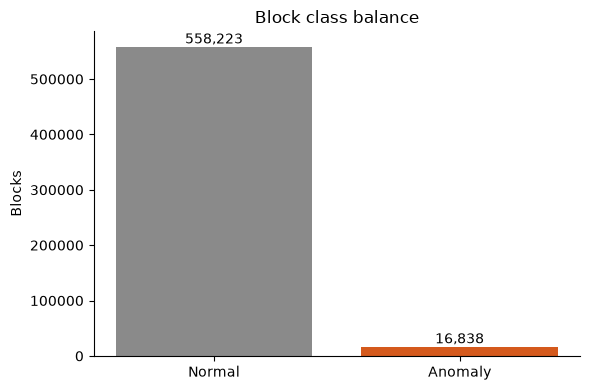

In [5]:
counts = df['target'].value_counts().sort_index()
anomaly_rate = counts[1] / counts.sum()
print('normal:', counts[0], ' anomaly:', counts[1], ' anomaly rate:', round(anomaly_rate, 6))

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Normal', 'Anomaly'], counts.values, color=[NORMAL_COLOUR, ANOMALY_COLOUR])
ax.bar_label(bars, labels=[f'{value:,}' for value in counts.values])
ax.set_title('Block class balance')
ax.set_ylabel('Blocks')
fig.tight_layout()
fig.savefig(figures / 'class_balance.png', dpi=160)
plt.show()

## How long is each block's log history?

The total number of events per block is a simple size measure. The y-axis is logarithmic because normal blocks outnumber anomalies by a wide margin.

median events per block, normal: 19.0  anomaly: 20.0


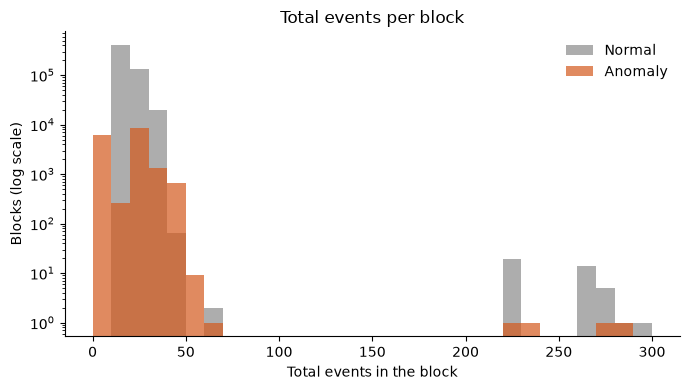

In [6]:
total_events = df[event_columns].sum(axis=1)
normal_totals = total_events[df['target'] == 0]
anomaly_totals = total_events[df['target'] == 1]
print('median events per block, normal:', normal_totals.median(), ' anomaly:', anomaly_totals.median())

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.arange(0, total_events.max() + 10, 10)
ax.hist(normal_totals, bins=bins, color=NORMAL_COLOUR, alpha=0.7, label='Normal')
ax.hist(anomaly_totals, bins=bins, color=ANOMALY_COLOUR, alpha=0.7, label='Anomaly')
ax.set_yscale('log')
ax.set_xlabel('Total events in the block')
ax.set_ylabel('Blocks (log scale)')
ax.set_title('Total events per block')
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(figures / 'total_events_by_class.png', dpi=160)
plt.show()

## Which events are common?

A handful of event types make up almost every log line. Many events are rare, and some appear only in anomalous blocks; notebook 02 looks at those.

E5     1723232
E26    1719741
E11    1706679
E9     1706514
E21    1402047
E23    1396174
E22     575061
E3      428726
E4      356207
E2      120036
E6        7097
E18       7002
E25       7002
E16       6937
E20       5545
E7        3416
E13       1464
E28       1288
E27        975
E14        155
E10        108
E15         65
E8          49
E29         47
E12         34
E1          10
E17          9
E19          5
E24          4
dtype: int64


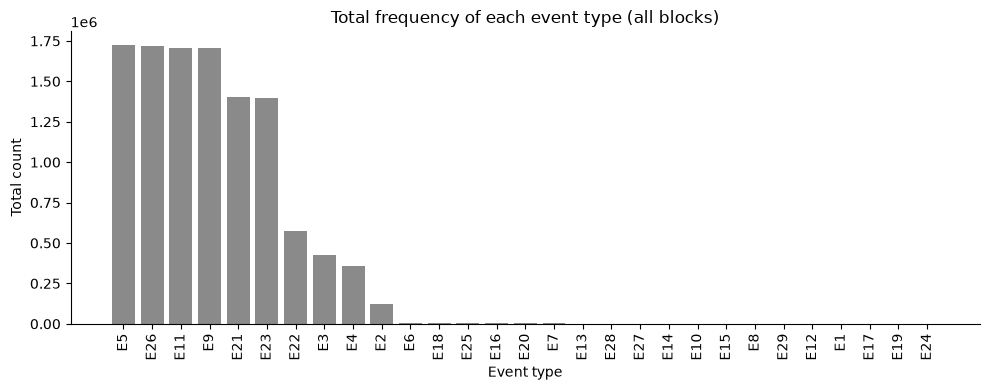

In [7]:
event_totals = df[event_columns].sum().sort_values(ascending=False)
print(event_totals)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(event_totals.index, event_totals.values, color=NORMAL_COLOUR)
ax.set_title('Total frequency of each event type (all blocks)')
ax.set_xlabel('Event type')
ax.set_ylabel('Total count')
ax.tick_params(axis='x', rotation=90)
fig.tight_layout()
fig.savefig(figures / 'event_frequency_overview.png', dpi=160)
plt.show()

## Save the clean table

Only `BlockId` (kept to line rows up, never used as a feature), the 29 event counts and `target` are saved.

In [8]:
clean = df[['BlockId'] + event_columns + ['target']]
clean.to_csv(processed / 'hdfs_clean.csv', index=False)
print('saved hdfs_clean.csv with shape', clean.shape)

saved hdfs_clean.csv with shape (575061, 31)


## One fixed split

1. A stratified 80/20 split separates the **test** set (20%). It is not touched until the final evaluation in notebook 03.
2. The remaining 80% is split again, stratified, into **training** (75% of it) and **validation** (25% of it). Validation is used to choose models and alarm thresholds.

That gives 60% / 20% / 20% of all blocks. Stratifying keeps the anomaly rate the same in every part, and `random_state=42` makes the split identical on every run.
The split stores row positions, not data, so every notebook reads the same rows from `hdfs_clean.csv`.

In [9]:
all_positions = np.arange(len(clean))

train_full_idx, test_idx = train_test_split(
    all_positions, test_size=0.2, stratify=clean['target'], random_state=42)

In [10]:
train_idx, validation_idx = train_test_split(
    train_full_idx, test_size=0.25, stratify=clean['target'].iloc[train_full_idx], random_state=42)

In [11]:
np.savez(processed / 'splits.npz', train_idx=train_idx, validation_idx=validation_idx, test_idx=test_idx)

parts = {'train': train_idx, 'validation': validation_idx, 'test': test_idx}
summary = []
for part_name, positions in parts.items():
    part_target = clean['target'].iloc[positions]
    summary.append({'part': part_name, 'blocks': len(positions),
                    'anomalies': int(part_target.sum()), 'anomaly_rate': part_target.mean()})
summary = pd.DataFrame(summary)
display(summary)

,part,blocks,anomalies,anomaly_rate
0,train,345036,10103,0.029281
1,validation,115012,3367,0.029275
2,test,115013,3368,0.029284


A last check: no block may appear in two parts, and together the parts must cover every block.

In [12]:
print('train & validation overlap:', len(np.intersect1d(train_idx, validation_idx)))
print('train & test overlap:', len(np.intersect1d(train_idx, test_idx)))
print('validation & test overlap:', len(np.intersect1d(validation_idx, test_idx)))
print('blocks covered:', len(train_idx) + len(validation_idx) + len(test_idx), 'of', len(clean))

train & validation overlap: 0
train & test overlap: 0
validation & test overlap: 0
blocks covered: 575061 of 575061


## Summary

- The clean table keeps only the 29 event counts as features; `Label` and `Type` from the matrix are dropped because they leak the answer.
- The split is saved once and reused by notebooks 02 and 03, so exploration (training part only), model choice (validation) and final reporting (test) never see each other's blocks.